# Accuracy of PyToF — full study

This is the complete convergence study behind the numbers in the README and behind the error estimates of `ToF.get_Js_errors()`. It takes **tens of minutes** on a multi-core machine (it uses all cores); the short version, [`accuracy_quick.ipynb`](accuracy_quick.ipynb), runs in about a minute and is the one to use when you just want to check that an installation works.

All studies use the Jupiter polytrope of Wisdom & Hubbard (2016), for which an exact solution exists, and compare

1. **without differential rotation** against the exact (Bessel function) solution, as a function of the number of grid points $N = 2^3 \ldots 2^{15}$ and the order, also against the ToF code of Movshovitz & Fortney (2022) ("M&F 22", orders 4 and 7 only; the folder `nmovshov_ToFPlanet`);
2. the same with **binning** of the figure functions, $N/n_\mathrm{bin} = 2^0 \ldots 2^{12}$;
3. **differential rotation** against the CMS method for two wind profiles (DR2 with four parameters, DR3 with ten).

Section 2 also produces the error tables `PyToF/accuracy_data_{simpson,trapezoid}.npz` used by `get_Js_errors()`. They are **only written if you set `WRITE_ACCURACY_DATA = True`** below, because that overwrites files of the package. Every figure is saved in `images/`.

In [1]:
import sys
import pathlib

import numpy as np
import matplotlib.pyplot as plt

# Optional personal matplotlib style: used if a file mpl_config.py exists in a
# folder above this one, silently ignored otherwise.
for parent in pathlib.Path.cwd().resolve().parents[:4]:
    if (parent / "mpl_config.py").exists():
        sys.path.insert(0, str(parent))
        break
try:
    from mpl_config import apply_mpl_opts

    apply_mpl_opts()
except ImportError:
    pass  # plain matplotlib defaults

from importlib.metadata import version

import helpers
import references

# --- settings ---------------------------------------------------------------
WRITE_ACCURACY_DATA = False  # True: overwrite PyToF/accuracy_data_*.npz with the results of section 2
PROCESSES = None  # number of worker processes; None: all cores
FAST = False  # True: sweep only N = 2^3 ... 2^11 (a few minutes) instead of 2^15
IMAGES = pathlib.Path("images")
# ---------------------------------------------------------------------------

print("python", sys.version.split()[0], "| numpy", version("numpy"), "| scipy", version("scipy"), "| matplotlib", version("matplotlib"))
Ns = 2 ** np.linspace(3, 11 if FAST else 15, 9 if FAST else 13)
steps = 2 ** np.arange(int(np.log2(Ns[-2])))
SHOW = [0, 1, 4, 11]  # figures to display here (R_eq/R_m, J_2, J_8, runtime); all are saved


def show(figs):
    """Show the selected figures, close the others (they are saved to disk)."""
    for i, fig in enumerate(figs):
        if i not in SHOW:
            plt.close(fig)

python 3.10.12 | numpy 2.2.6 | scipy 1.15.3 | matplotlib 3.10.1


## 1 · No differential rotation, no binning

Solid lines: PyToF with Simpson's rule; dashed lines: Movshovitz & Fortney (2022). The M&F code solves the same problem with a different implementation (trapezoid-based integrals and a different iteration), orders 4 and 7. The error of PyToF is limited by the grid for small $N$ and by the order for large $N$; compare the lower right panel for the cost.

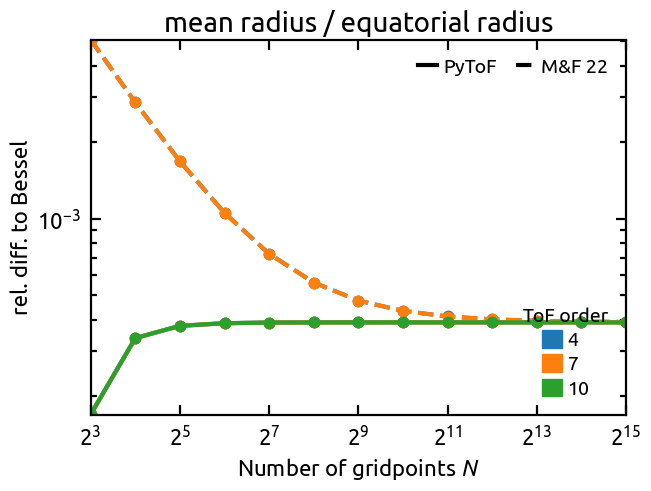

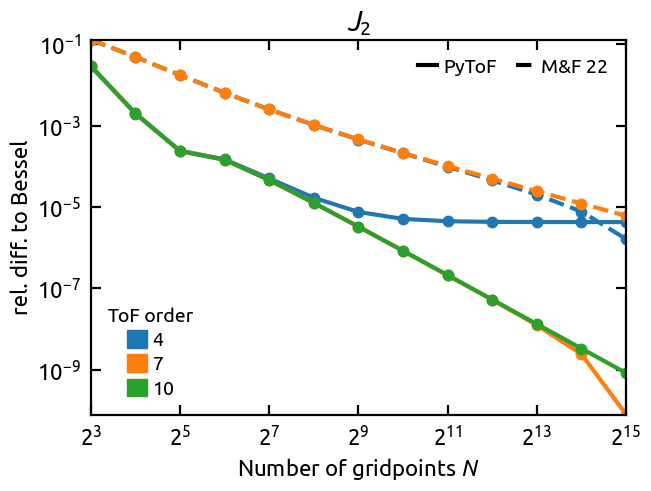

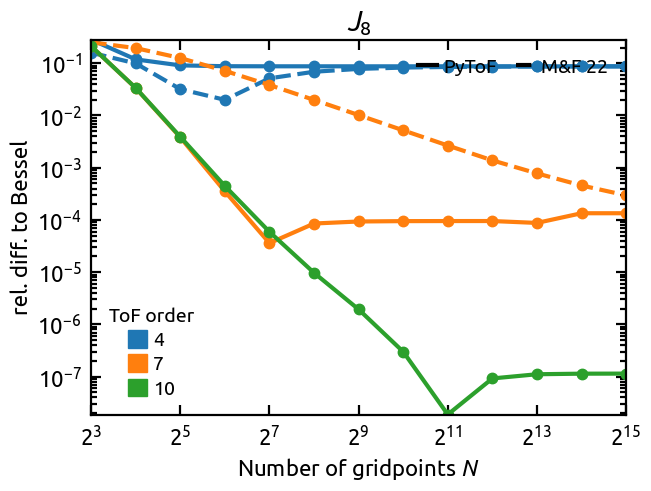

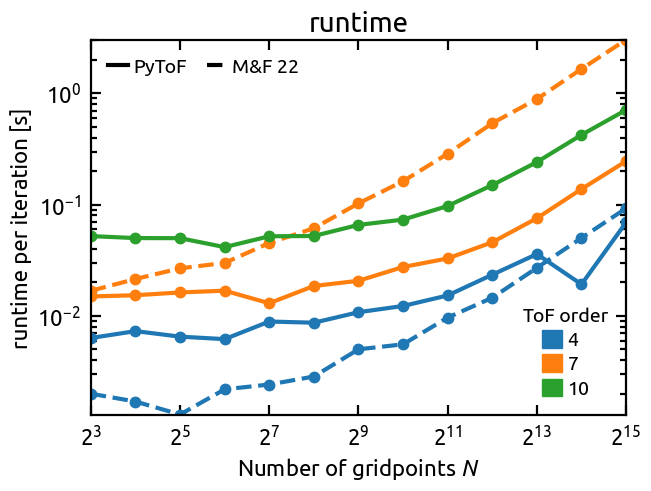

In [2]:
movs = helpers.sweep_movshovitz(Ns, processes=PROCESSES, progress=False)
sweep = helpers.sweep_pytof(Ns, steps=(1,), processes=PROCESSES, progress=False)
figs = helpers.plot_convergence(Ns, references.Bessel, "Bessel", sweep, movshovitz=movs, outdir=IMAGES, prefix="Bessel_")
show(figs)

## 2 · Binning

`n_bin < N` computes the figure functions on `n_bin` points and interpolates; the color encodes $N/n_\mathrm{bin}$ (dark: no binning). Binning by a modest factor costs no accuracy and saves time at large $N$; for large factors the interpolation error dominates.

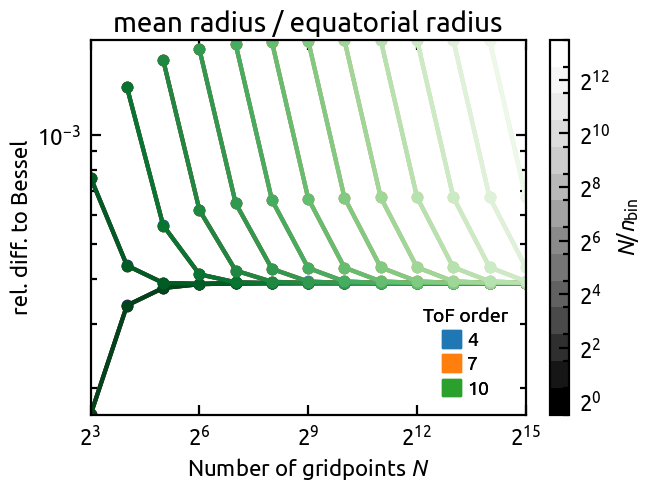

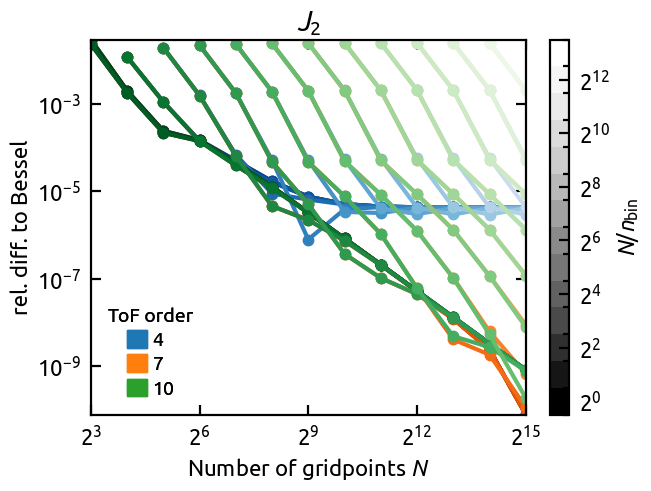

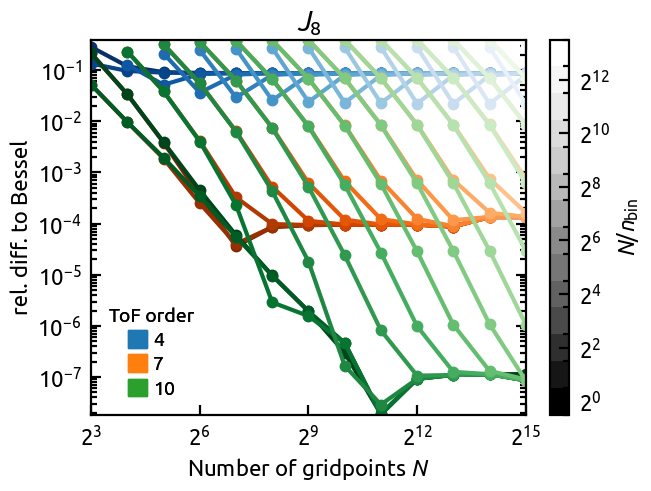

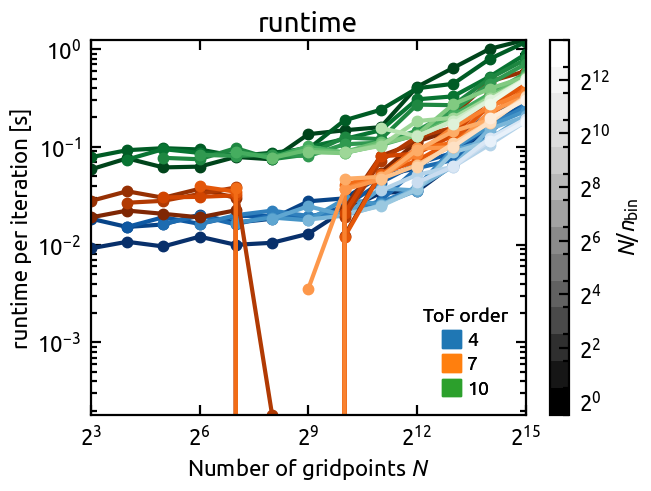

In [3]:
sweep_bin = helpers.sweep_pytof(Ns, steps=steps, processes=PROCESSES, progress=False)
figs = helpers.plot_convergence(Ns, references.Bessel, "Bessel", sweep_bin, steps=steps, outdir=IMAGES, prefix="Binning_Bessel_")
show(figs)

### Error tables for `get_Js_errors()`

The relative errors of the sweeps above, for Simpson's rule (just computed) and for the trapezoid rule (computed now), are what `get_Js_errors()` looks up. First a check against the tables that ship with the package: the values should agree exactly if the numerics did not change since they were made.

In [4]:
tables_simpson = helpers.error_tables(Ns, steps, sweep_bin)
sweep_trapezoid = helpers.sweep_pytof(Ns, steps=steps, use_simpson=False, processes=PROCESSES, progress=False)
tables_trapezoid = helpers.error_tables(Ns, steps, sweep_trapezoid)

if not FAST:
    for name, new in (("simpson", tables_simpson), ("trapezoid", tables_trapezoid)):
        old = np.load(helpers.ROOT / "PyToF" / f"accuracy_data_{name}.npz")
        for key in ("rel_error_04", "rel_error_07", "rel_error_10"):
            both = np.isfinite(new[key]) & np.isfinite(old[key])
            dev = np.max(np.abs(new[key][both] / old[key][both] - 1))
            print(f"{name:9s} {key}: largest relative deviation from the shipped table: {dev:.1e}")

if WRITE_ACCURACY_DATA:
    for name, tables in (("simpson", tables_simpson), ("trapezoid", tables_trapezoid)):
        np.savez(helpers.ROOT / "PyToF" / f"accuracy_data_{name}.npz", **tables)
    print("wrote PyToF/accuracy_data_{simpson,trapezoid}.npz")
else:
    print("(PyToF/accuracy_data_*.npz not modified; set WRITE_ACCURACY_DATA = True to write them)")

simpson   rel_error_04: largest relative deviation from the shipped table: 0.0e+00
simpson   rel_error_07: largest relative deviation from the shipped table: 0.0e+00
simpson   rel_error_10: largest relative deviation from the shipped table: 0.0e+00
trapezoid rel_error_04: largest relative deviation from the shipped table: 0.0e+00
trapezoid rel_error_07: largest relative deviation from the shipped table: 0.0e+00
trapezoid rel_error_10: largest relative deviation from the shipped table: 0.0e+00
(PyToF/accuracy_data_*.npz not modified; set WRITE_ACCURACY_DATA = True to write them)


## 3 · Differential rotation

With barotropic differential rotation PyToF is compared with the CMS results of Wisdom & Hubbard (2016) for two wind profiles (DR2: four parameters; DR3: ten parameters; the parameters are in `references.py`). The CMS method has its own numerical error, which for the higher moments is larger than that of PyToF, so the curves flatten where the *reference* stops converging (DR3 is noisy beyond $J_{14}$).

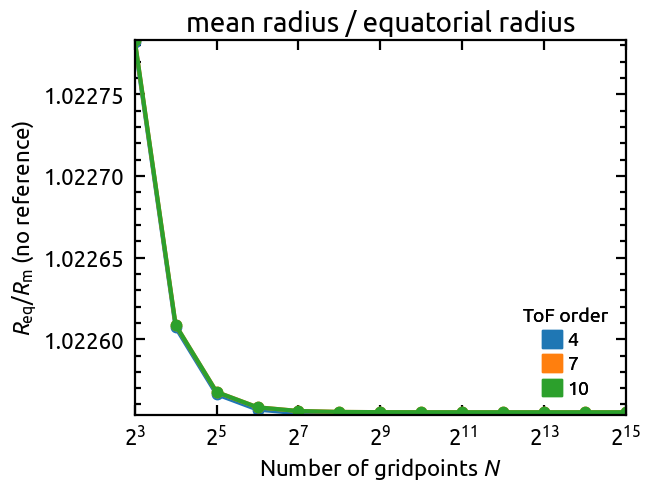

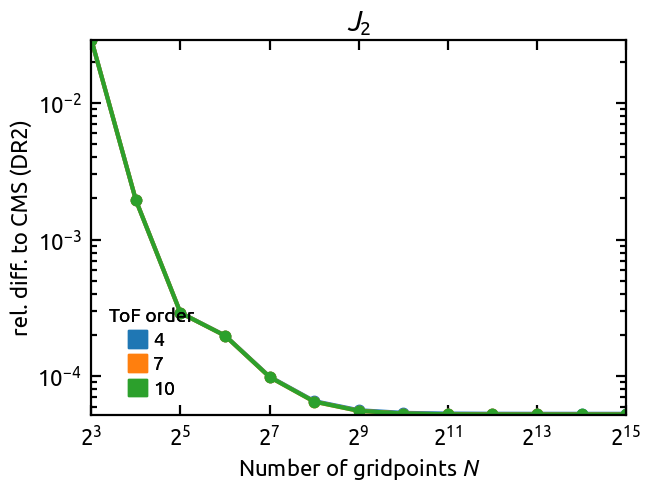

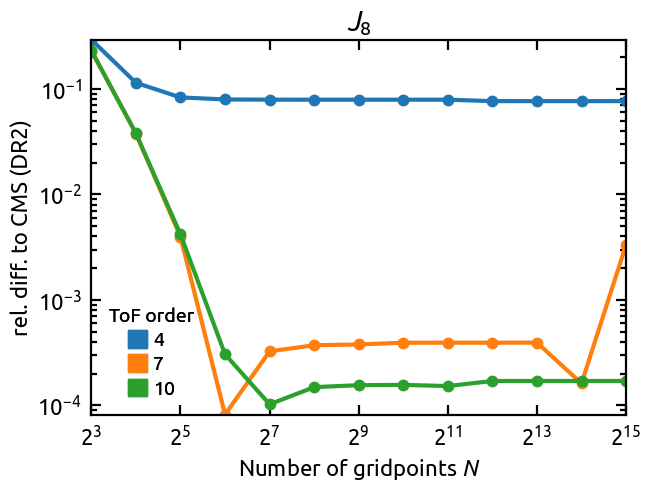

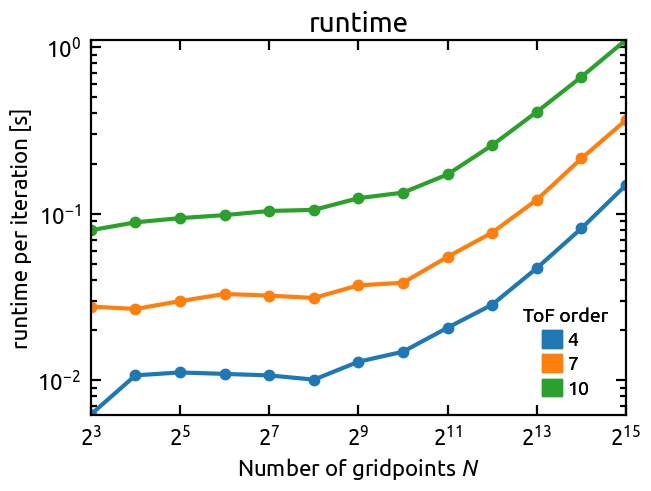

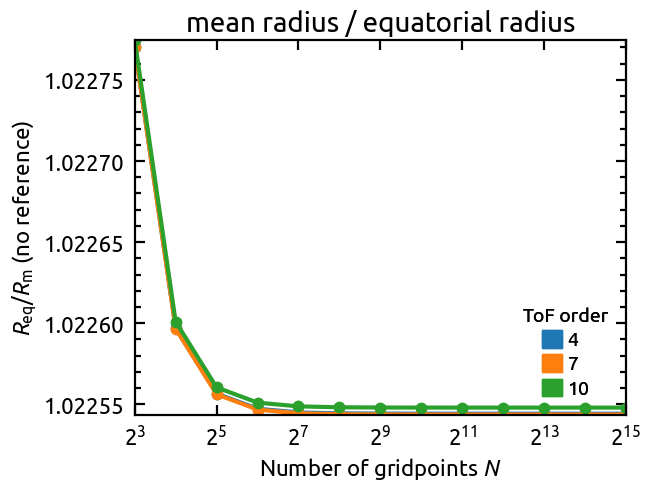

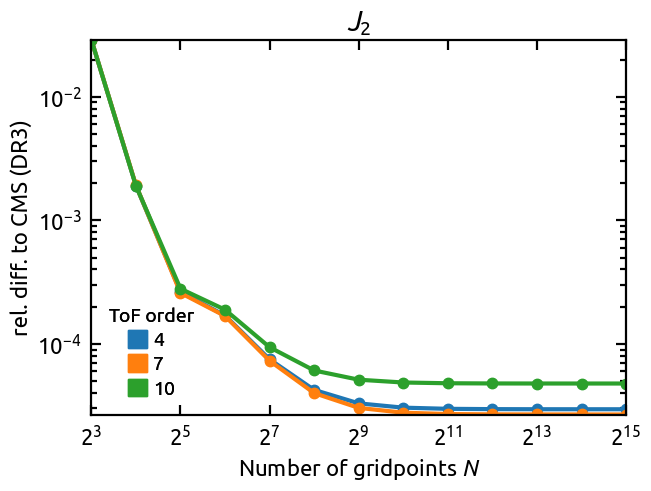

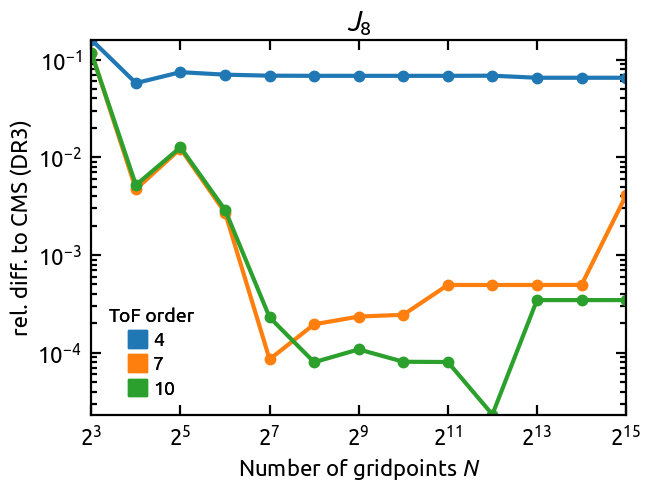

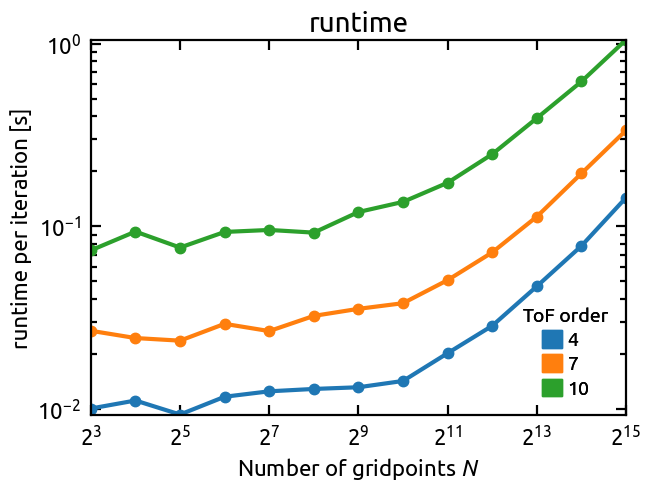

In [5]:
for name, ref, alphas in (
    ("CMS (DR2)", references.CMSDR2, references.alphas_array(references.ALPHAS_DR2)),
    ("CMS (DR3)", references.CMSDR3, references.alphas_array(references.ALPHAS_DR3)),
):
    sweep_dr = helpers.sweep_pytof(Ns, steps=(1,), alphas=alphas, processes=PROCESSES, progress=False)
    figs = helpers.plot_convergence(Ns, ref, name, sweep_dr, outdir=IMAGES, prefix=f"{name}_")
    show(figs)